# Policy Gradient Basics

## 📚 Learning Objectives

By completing this notebook, you will:
- Implement a simple policy gradient method
- Use rewards and baseline to reduce variance

## 🔗 Where this fits

**Builds on:** Course 08 (AIAT 122) — Unit 4, lesson 03 "Reinforcement Learning: DQN and Policy Gradients" — policy gradients were introduced there as an idea; here you write the REINFORCE update in PyTorch and see why a baseline is needed before its variance is manageable.

**Used later in:** Course 10 (AIAT 124) — Unit 2 (lesson 03 "Prompt Engineering") and Unit 5 (lesson 02 "Future Trends and Research"), where RLHF is named as what turns a raw language model into one that follows instructions; RLHF is a policy-gradient method with a learned reward.


## Lesson Brief

This lesson gives students their first look at **policy gradient** methods.

Instead of learning action values and choosing the best one, the agent learns parameters of the policy directly.

Why this matters: this is the conceptual doorway to actor-critic methods, PPO, and many modern RL systems.

Students should leave this lesson understanding the shift from value tables to direct policy optimization.


## 🌍 Real case: REINFORCE, running on YouTube

REINFORCE is from 1992 (Williams) and it is easy to file under "historical". It is not. Chen, Beutel,
Covington, Jain, Belletti and Chi of Google published "Top-K Off-Policy Correction for a REINFORCE
Recommender System" (WSDM 2019), describing a REINFORCE policy-gradient recommender **running in
production on YouTube**, choosing videos from a catalogue of millions.

The measured live results are worth reading precisely because they are small:

- Feeding *exploratory* data into training — 5% of users served by a stochastic policy — produced a
  statistically significant **+0.07% ViewTime**.
- Adding off-policy correction produced no significant ViewTime change but **+0.53% more videos
  viewed**.
- The top-K off-policy correction produced **+0.85% ViewTime**.

Under 1% each. At YouTube's scale those are enormous; on a slide they look like nothing. Learn to
read both facts at once — it is the single most useful habit for talking about deployed RL.

Note also what the paper had to fix, because it is the honest cost of policy gradients: the logged
data came from *previous* recommenders, not from the policy being trained. Plain REINFORCE is
on-policy and cannot use that data correctly, so most of the paper is about the correction that makes
it possible.

**What goes wrong without this.** Value-based methods (Unit 2, and the DQN you just built) learn a
number per action and then act greedily on it. That requires enumerable actions and gives you a
deterministic policy. A recommender needs to output a *distribution* over millions of items, and a
robot needs continuous torques. Policy gradients optimise the policy directly, which is the only
approach that answers either need.


## Recommended YouTube Video

To reinforce this lesson, watch **David Silver - "RL Course Lecture 7: Policy Gradient Methods"**:
[Watch on YouTube](https://www.youtube.com/watch?v=KHZVXao4qXs)

Why this pick:
- Explains the shift from value-based RL to direct policy optimization.
- Strong fit for students meeting policy gradients for the first time.

## Student Support Pack

Use this section as a checkpoint before and after the main code cells so the idea stays clearer than the syntax.

### Key Terms
- Agent: the decision maker.
- Environment: the world it acts in.
- Reward: feedback signal.
- Return: long-term reward total.

### Quick Check
- What core RL idea does this notebook teach?
- Which output best reflects the main concept?
- How would you explain this topic in one minute?

### Common Mistakes
- Focusing on syntax before meaning.
- Reading outputs without connecting them to the concept.
- Missing how one step fits the whole RL loop.


## Real-World Context

Policy gradient methods are what you reach for when a value table and an argmax over actions will not do the job: continuous action spaces such as robot joint control, and settings where the policy itself must stay stochastic. They are also the family behind RLHF fine-tuning of instruction-following language models.

In [1]:
# Lesson opener: state the one idea that separates policy-gradient methods from value methods.
# Everything the REINFORCE example below does hangs on this switch of what gets learned.

import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("Policy Gradient Basics")
print("=" * 70)

# The key contrast, printed where students start reading.
print("\nValue-based methods (Q-learning, DQN): learn VALUES, then act greedily on them.")
print("Policy-gradient methods (REINFORCE):   learn the POLICY itself — a probability")
print("distribution over actions — and nudge it toward actions that earned high returns.")

# Roadmap for the cells below.
print("\nUp next: a REINFORCE agent on CartPole. Watch for three ingredients:")
print("  1. a small network that outputs action PROBABILITIES (softmax)")
print("  2. complete-episode RETURNS (no bootstrapping)")
print("  3. normalized returns acting as a simple BASELINE to reduce variance")

Policy Gradient Basics

Value-based methods (Q-learning, DQN): learn VALUES, then act greedily on them.
Policy-gradient methods (REINFORCE):   learn the POLICY itself — a probability
distribution over actions — and nudge it toward actions that earned high returns.

Up next: a REINFORCE agent on CartPole. Watch for three ingredients:
  1. a small network that outputs action PROBABILITIES (softmax)
  2. complete-episode RETURNS (no bootstrapping)
  3. normalized returns acting as a simple BASELINE to reduce variance


## 🌍 Industry-Motivated Worked Example — REINFORCE on CartPole

> **What is real here and what is not.** The industry uses below are real, and CartPole-v1
> is a real, standard Gymnasium benchmark that anyone can rerun — the physics simulation and
> the observations are not invented for this lesson. But a cart and a pole are not a robot or
> a car. Treat CartPole as the smallest honest test bed for the algorithm, not as evidence
> about the systems named below.

**Industry context:**
- Modern RL systems often use more advanced policy-gradient relatives such as PPO
- Boston Dynamics uses policy-gradient-style control methods in robotics research
- Robotic surgery systems can use policy optimization ideas for precise sequential decisions

We implement **REINFORCE** (the simplest policy gradient) on CartPole-v1.

Teaching note: REINFORCE is best presented here as an early member of the same family, not as a direct stand-in for RLHF systems.

## ✍️ Your turn — work out what the baseline does to one short episode

<!-- YOUR_TURN_COURSE09 -->

The training cell below computes each step's discounted return-to-go with `GAMMA = 0.99`, then normalises the returns of the episode (subtract their mean, divide by their standard deviation) before multiplying each step's `log_prob` by its return. Take an episode that lasted exactly **4 steps**, every reward **+1**.

1. `returns_to_go` — the four discounted returns, first step first.
2. `n_pushed_down` — how many of the four actions have their probability pushed **down** after normalisation.
3. `last_step_sign_without_baseline` — `"+"` or `"-"`: the sign of the last step's signal if the normalisation line were deleted.

**Expected shape:** a list of four numbers (the check accepts ±0.01 each), one whole number, one sign. PyTorch's `.std()` divides by n − 1; the sign pattern does not depend on that choice.


In [2]:
# ✍️ Your turn — replace the None values, then run this cell and the check below.
returns_to_go = None                     # four discounted returns, first step first (GAMMA = 0.99)
n_pushed_down = None                     # actions whose probability falls after normalisation
last_step_sign_without_baseline = None   # "+" or "-" if the returns were NOT normalised


In [3]:
# ✅ Check — recomputes the four-step episode by hand; prints a verdict, never raises.
try:
    if returns_to_go is None and n_pushed_down is None and last_step_sign_without_baseline is None:
        print("Your turn: not attempted yet.")
    else:
        _G, _ref = 0.0, []
        for _r in [1.0, 1.0, 1.0, 1.0][::-1]:
            _G = _r + 0.99 * _G; _ref.insert(0, _G)
        _mean = sum(_ref) / 4
        _n_down = sum(1 for g in _ref if g - _mean < 0)
        if returns_to_go is None:
            print("1. returns_to_go: not attempted yet.")
        elif len(returns_to_go) == 4 and all(abs(a - b) <= 0.01 for a, b in zip(returns_to_go, _ref)):
            print("1. returns_to_go: matches.")
        else:
            print("1. returns_to_go: does not match. Hint: walk the episode BACKWARDS; the last step's return is its own reward, each earlier one adds 0.99 times the next.")
        if n_pushed_down is None:
            print("2. n_pushed_down: not attempted yet.")
        elif n_pushed_down == _n_down:
            print("2. n_pushed_down: matches.")
        else:
            print("2. n_pushed_down: does not match. Hint: after subtracting the mean, which returns are negative? Those steps get a negative signal.")
        if last_step_sign_without_baseline is None:
            print("3. last_step_sign_without_baseline: not attempted yet.")
        elif str(last_step_sign_without_baseline).strip() == "+":
            print("3. last_step_sign_without_baseline: matches.")
        else:
            print("3. last_step_sign_without_baseline: does not match. Hint: without the baseline the signal IS the raw return, and every return on CartPole is positive.")
except Exception as e:
    print(f"Check could not run ({type(e).__name__}: {e}). Fix the attempt and re-run.")


Your turn: not attempted yet.


Episode   0 | Avg reward: 13.0
Episode  50 | Avg reward: 16.4
Episode 100 | Avg reward: 31.5


Episode 150 | Avg reward: 56.7


Episode 200 | Avg reward: 129.9


Episode 250 | Avg reward: 296.4


Episode 300 | Avg reward: 341.4


Episode 350 | Avg reward: 407.9


Episode 400 | Avg reward: 420.6


Episode 450 | Avg reward: 491.1


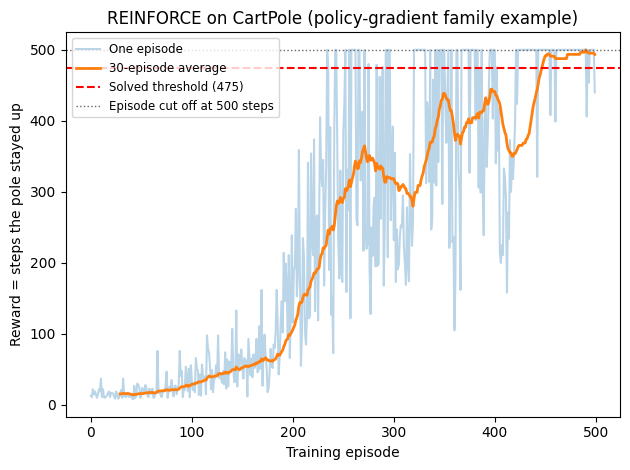

In [4]:
import torch, torch.nn as nn, torch.optim as optim
import gymnasium as gym
import numpy as np, matplotlib.pyplot as plt

# Fix the random seeds (PyTorch draws the actions, so its seed decides the run) so the
# training curve you see is the same one described in the caption underneath it.
torch.manual_seed(42); np.random.seed(42)
env = gym.make('CartPole-v1')
# Seed the environment as well, so every episode starts from the same sequence of start states.
env.reset(seed=42); env.action_space.seed(42)

class PolicyNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 128), nn.ReLU(),
            nn.Linear(128, 2), nn.Softmax(dim=-1)
        )
    def forward(self, x): return self.net(x)

policy  = PolicyNet()
opt     = optim.Adam(policy.parameters(), lr=2e-3)
# Set discount factor gamma used inside r + gamma * V(s') targets.
GAMMA   = 0.99; ep_rewards = []

for episode in range(500):
    obs,_ = env.reset(); log_probs=[]; rewards_ep=[]
    for _ in range(500):
        probs  = policy(torch.tensor(obs).float().unsqueeze(0))
        dist   = torch.distributions.Categorical(probs)
        action = dist.sample()
        log_probs.append(dist.log_prob(action))
        obs, r, done, trunc, _ = env.step(action.item())
        rewards_ep.append(r)
        if done or trunc: break

    # ── Compute discounted returns ──────────────────────────────────────────
    G = 0; returns = []
    for r in reversed(rewards_ep):
        G = r + GAMMA*G; returns.insert(0, G)
    returns = torch.tensor(returns).float()
    returns = (returns - returns.mean()) / (returns.std() + 1e-8)

    # ── Policy gradient loss ────────────────────────────────────────────────
    loss = -torch.stack([lp*R for lp,R in zip(log_probs, returns)]).sum()
    opt.zero_grad(); loss.backward(); opt.step()
    ep_rewards.append(sum(rewards_ep))
    if episode%50==0: print(f"Episode {episode:3d} | Avg reward: {np.mean(ep_rewards[-20:]):.1f}")

env.close()
ma = np.convolve(ep_rewards, np.ones(30)/30, 'valid')
# Thin line: every single episode. It is deliberately faint — the scatter IS the lesson.
plt.plot(ep_rewards, alpha=0.3, label="One episode")
# Thick line: the 30-episode average, the trend you can actually read through the noise.
plt.plot(np.arange(len(ma)) + 29, ma, lw=2, label="30-episode average")
# The score Gymnasium calls "solved" for CartPole-v1.
plt.axhline(475, color='red', linestyle='--', label="Solved threshold (475)")
# The environment cuts every episode off at 500 steps, so the flat top is a ceiling, not a plateau.
plt.axhline(500, color='0.4', linestyle=':', lw=1, label="Episode cut off at 500 steps")
plt.title("REINFORCE on CartPole (policy-gradient family example)")
# Name both axes in words, so the picture can be read without the code.
plt.xlabel("Training episode")
plt.ylabel("Reward = steps the pole stayed up")
# Legend goes top-left, the one corner of this plot with no data in it.
plt.legend(loc="upper left", fontsize=8.5)
plt.tight_layout(); plt.show()

### 👁️ Read the figure

**What it shows.** One faint blue point per training episode — how many steps the pole stayed up — with the
thick orange line the 30-episode average through them. Red dashed is the "solved" score; the grey dotted line
at 500 is where the environment cuts every episode off, which is why nothing rises above it.

**What to see.** Two different stories, and you need both. The orange average is the good news: from about 15
steps at the start to the solved line by the end of the 500 episodes, learning the policy directly with no
value table anywhere.
The faint blue cloud is the bad news, and it is what makes this figure worth printing. Even after episode 400,
with the average above 400, single episodes still drop as low as 179 steps. And the orange line itself sags
twice on the way up: it reaches about 395 steps by episode 295 and is back down at about 315 by episode 320,
then reaches about 455 by episode 400 and falls to about 390 by episode 425 — stretches of tens of episodes
where the agent got measurably *worse*.

**What it proves.** REINFORCE learns, and REINFORCE is loud. Each update is scaled by one whole-episode return
that can be anything from 9 to 500, so the gradient is an extremely noisy estimate of the right direction; the
sags and the scatter are that noise made visible, not a bug in the code. Keep this picture in mind for the next
two lessons: the critic in actor-critic and the clipped update in PPO are both answers to exactly the spread you
see in this blue cloud.

## CartPole step-through (GIF + slider)

Policy-gradient code optimizes **expected return** from the same **Gymnasium** stepping loop you learned in Unit 1. This cell shows **CartPole pixels** for a short **random** episode so you can scrub timesteps beside the math.


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


15 frames | return=14.0 | term=True | trunc=False


objc[16567]: Class SDL_RumbleMotor is implemented in both /opt/homebrew/Cellar/sdl2/2.32.10/lib/libSDL2-2.0.0.dylib (0x11d280138) and /Users/abdullah/Downloads/AI Diploma/.venv/lib/python3.14/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x11d77c9c8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[16567]: Class SDL_RumbleContext is implemented in both /opt/homebrew/Cellar/sdl2/2.32.10/lib/libSDL2-2.0.0.dylib (0x11d280188) and /Users/abdullah/Downloads/AI Diploma/.venv/lib/python3.14/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x11d77ca18). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[16567]: Class SDLApplication is implemented in both /opt/homebrew/Cellar/sdl2/2.32.10/lib/libSDL2-2.0.0.dylib (0x11d27fc88) and /Users/abdullah/Downloads/AI Diploma/.venv/lib/python3.14/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x11d77ca68). T

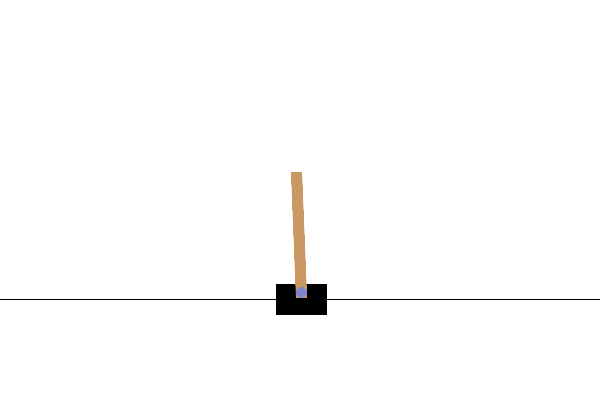

In [5]:
# Motion recap (optional visual): replay one CartPole episode as a GIF + step slider via the shared Course 09 helper.
# Why: watching the cart and pole move frame-by-frame connects the training numbers above to real behaviour.

%pip install ipywidgets pillow -q

import pathlib
import sys

# Find the shared Course 09 helper (course09_step_viz.py) from ANY folder, and on Google Colab.
# WHAT: look for the helper up the folder chain, then inside a "Course 09" folder on that chain,
#       and only then download it; finally put its folder on Python's import path.
# WHY:  searching only the PARENTS of the working directory breaks the moment you open this
#       notebook from the repository root - there the helper sits in a child folder, not a
#       parent - and on Colab there is no repository at all. This does not care where you
#       started the kernel from.
_HELPER_C9 = "course09_step_viz.py"
_chain_c9 = [pathlib.Path.cwd().resolve(), *pathlib.Path.cwd().resolve().parents]
_course09 = next((d for d in _chain_c9 if (d / _HELPER_C9).exists()), None)
if _course09 is None:                      # opened from the repo root, or from another course
    _course09 = next((d / "Course 09" for d in _chain_c9
                      if (d / "Course 09" / _HELPER_C9).exists()), None)
if _course09 is None:                      # Google Colab, or a stray copy of this notebook
    import urllib.request
    try:
        urllib.request.urlretrieve(
            "https://raw.githubusercontent.com/A-Alwabel/AI-Diploma-Program/main/"
            "Course%2009/" + _HELPER_C9, _HELPER_C9)
    except Exception as _e:
        raise FileNotFoundError(
            f"Could not find {_HELPER_C9} from this folder, and could not download it either. "
            "Open this notebook inside a clone of "
            "https://github.com/A-Alwabel/AI-Diploma-Program, or connect to the internet and "
            f"re-run this cell. (underlying error: {_e})") from None
    _course09 = pathlib.Path.cwd()

# Put that folder on Python's import path so the helper imports from any unit folder.
if str(_course09) not in sys.path:
    sys.path.insert(0, str(_course09))

import gymnasium as gym
# cs9viz turns recorded environment frames into an animated GIF plus a step-by-step slider.
import course09_step_viz as cs9viz

# Create the environment in rgb_array mode so every step can be captured as an image frame.
env_vis = gym.make("CartPole-v1", render_mode="rgb_array")


# Random policy: pick any action with equal chance — the 'no learning yet' baseline behaviour.
def random_policy(obs, step):
    return int(env_vis.action_space.sample())


# Play one episode with this policy, saving one frame per step (a fixed seed keeps the run reproducible).
frames, total_r, term, trunc = cs9viz.collect_rollout_frames(
    env_vis, random_policy, max_steps=100, seed=0
)
env_vis.close()

print(f"{len(frames)} frames | return={total_r:.1f} | term={term} | trunc={trunc}")
# Replay the episode as an animation, then as a slider you can scrub step by step — motion connects the numbers to behaviour.
cs9viz.display_gif(frames, duration_ms=110)
cs9viz.display_step_slider(frames, title="CartPole-v1 timestep")

In [6]:
# References (shown with Markdown inside a Python cell — avoids SyntaxError if a Markdown block is run as code.)
# Seminal papers first, then recent landmarks and surveys; linked entries were checked against their arXiv/publisher pages.
from IPython.display import Markdown, display

display(Markdown(r"""## 📚 References

1. Williams, R. J. (1992). *Simple Statistical Gradient-Following Algorithms for Connectionist Reinforcement Learning* (REINFORCE). Machine Learning, 8. <https://link.springer.com/article/10.1007/BF00992696>
2. Mnih, V., Badia, A. P., Mirza, M. et al. (2016). *Asynchronous Methods for Deep Reinforcement Learning* (A3C). ICML. <https://arxiv.org/abs/1602.01783>
3. Schulman, J., Wolski, F., Dhariwal, P., Radford, A. & Klimov, O. (2017). *Proximal Policy Optimization Algorithms* (PPO). arXiv:1707.06347. <https://arxiv.org/abs/1707.06347>
4. Ouyang, L., Wu, J., Jiang, X. et al. (2022). *Training Language Models to Follow Instructions with Human Feedback* (InstructGPT — RLHF fine-tuning with PPO). NeurIPS. <https://arxiv.org/abs/2203.02155>
5. Shao, Z., Wang, P., Zhu, Q., Xu, R., Song, J., Bi, X., Zhang, H., Zhang, M., Li, Y. K., Wu, Y., & Guo, D. (2024). *DeepSeekMath: Pushing the Limits of Mathematical Reasoning in Open Language Models*. arXiv preprint. <https://arxiv.org/abs/2402.03300> (introduces GRPO: the same REINFORCE-style estimator you write in this notebook, with the baseline computed from a group of sampled answers to one prompt instead of a value network)
6. Luo, X., Zhang, Y., He, Z., Wang, Z., Zhao, S., Li, D., Qiu, L. K., & Yang, Y. et al. (2025). *Agent Lightning: Train ANY AI Agents with Reinforcement Learning*. arXiv preprint. <https://arxiv.org/abs/2508.03680> (policy-gradient training applied to an existing tool-using agent, with training decoupled from the agent's implementation)
"""))

## 📚 References

1. Williams, R. J. (1992). *Simple Statistical Gradient-Following Algorithms for Connectionist Reinforcement Learning* (REINFORCE). Machine Learning, 8. <https://link.springer.com/article/10.1007/BF00992696>
2. Mnih, V., Badia, A. P., Mirza, M. et al. (2016). *Asynchronous Methods for Deep Reinforcement Learning* (A3C). ICML. <https://arxiv.org/abs/1602.01783>
3. Schulman, J., Wolski, F., Dhariwal, P., Radford, A. & Klimov, O. (2017). *Proximal Policy Optimization Algorithms* (PPO). arXiv:1707.06347. <https://arxiv.org/abs/1707.06347>
4. Ouyang, L., Wu, J., Jiang, X. et al. (2022). *Training Language Models to Follow Instructions with Human Feedback* (InstructGPT — RLHF fine-tuning with PPO). NeurIPS. <https://arxiv.org/abs/2203.02155>
5. Shao, Z., Wang, P., Zhu, Q., Xu, R., Song, J., Bi, X., Zhang, H., Zhang, M., Li, Y. K., Wu, Y., & Guo, D. (2024). *DeepSeekMath: Pushing the Limits of Mathematical Reasoning in Open Language Models*. arXiv preprint. <https://arxiv.org/abs/2402.03300> (introduces GRPO: the same REINFORCE-style estimator you write in this notebook, with the baseline computed from a group of sampled answers to one prompt instead of a value network)
6. Luo, X., Zhang, Y., He, Z., Wang, Z., Zhao, S., Li, D., Qiu, L. K., & Yang, Y. et al. (2025). *Agent Lightning: Train ANY AI Agents with Reinforcement Learning*. arXiv preprint. <https://arxiv.org/abs/2508.03680> (policy-gradient training applied to an existing tool-using agent, with training decoupled from the agent's implementation)


## 💬 Discuss

The REINFORCE run above: 20-episode average reward **13.0 → 16.4 → 31.5 → 56.7 → 129.9 → 245.3 →
386.1 → 365.6 → 454.8 → 449.8** at episodes 0, 50, …, 450. Argue these out.

1. The printed average slipped from 386.1 at episode 300 to 365.6 at episode 350, and the figure's
   30-episode line sags twice on the way up (about 395 → 315 around episodes 295–320, about 455 → 390
   around 400–425). Explain what in the REINFORCE update makes this kind of collapse likely — and say what you would do about
   it if this were a deployed system rather than a notebook. (The next two lessons are two different
   answers to this question; predict them.)
2. YouTube's best reported gain was +0.85% ViewTime. Your CartPole agent went from 13 to about 450 —
   more than a thirty-fold improvement. Why is the 0.85% the more impressive number? Write the explanation you
   would give a non-technical manager.
3. The YouTube system had to serve 5% of real users a deliberately randomised policy to collect
   exploratory data. Suppose the product is a Saudi bank's app recommending financial products. Would
   you run that 5% bucket? What would you need from compliance, and what would you change about the
   design if the answer were no?


## 📝 Summary

You learned **Policy Gradient** methods that directly optimize the policy without a value table. **Actor-Critic** combines a policy (actor) with a value estimator (critic) for lower variance. **PPO** is a later, more stable member of the same policy-optimization family and is widely used in modern RL practice.

## ⚠️ Where this breaks

**The assumption that has to hold:** you can afford to throw your data away after one update.
REINFORCE is on-policy — the moment the policy changes, the episodes you collected under the old one
are, strictly, no longer usable.

- **Variance is the defining problem.** The gradient is scaled by the whole-episode return, which on
  CartPole ranges from 9 to 500. That is why the curve above collapses and recovers. Normalising the
  returns (the baseline in the code below) helps; it does not solve it. Actor-critic (next lesson) and
  PPO (lesson 04) are two further attempts at the same problem.
- **Sample hunger.** No replay buffer, no reuse. Every gradient step costs fresh episodes. DQN can
  learn ten times from one transition; REINFORCE learns once and discards it.
- **Logged data needs correction to be usable at all.** This is not a footnote — it is most of the
  YouTube paper. If your data was collected by a previous system (and in industry it always was),
  plain REINFORCE will optimise for the wrong distribution and you will not see it in the training
  curve.
- **Local optima are real.** Policy gradients follow the gradient of the policy's own performance. A
  policy that never tries an action gets no gradient signal about it, so a confidently wrong policy
  can be stable. This is the exploration problem of Unit 4 wearing different clothes.
- **Cheaper alternative:** if your action set is small and discrete and you want a deterministic
  policy you can inspect, value-based methods are simpler, more sample-efficient and easier to debug.
  Reach for policy gradients when the action space is continuous, or enormous, or when you genuinely
  need a stochastic policy — a randomised recommender, or a game where being predictable loses.


## Closing Takeaway

**Teaching takeaway:** Policy gradient methods learn the policy directly by increasing the probability of actions that lead to better returns.

**If students remember one idea:** Sometimes the goal is not to estimate a table of values first, but to optimize the policy itself.

**Quick check before moving on:**
- Can you explain why policy gradient methods work with action probabilities?
- Can you describe what signal tells the algorithm to increase or decrease an action probability?

**Bridge to the next step:** The next lesson returns to value estimation so students can compare direct policy learning with return-based estimation.

**For weaker coders:** After you run the important cells, write one sentence: *what number or plot changed, and does that match what the lesson said should happen?* If not, re-read only the `#` hint lines in that cell—not every line of Python.


## Did you understand? (about 2 minutes)

<!-- STUDENT_SELF_CHECK_COURSE09 -->

Answer **without scrolling** first. Then scroll only to compare with the notebook.

1. **One sentence:** What is the *single main idea* you are supposed to carry to the next lesson?
2. **Trace one step:** Pick one moment from this notebook (a number you printed, a plot, a table, or a GIF/slider frame). Write **state → action → reward → next state** in your own words — even if your “state” is a vector or a tile index.
3. **One honest confusion:** Write one question you still have. That question is what you should bring to class, study group, or office hours.

**If any answer is blank:** run the notebook again from the top **slowly** (run one cell → read the output → only then run the next).

**Remember:** a clean run means the code worked — it does **not** automatically mean every idea clicked. Confusion is normal until you can do steps 1–2 in plain language.
